# YojanaMitra — Clause Triage Classification

**NLP Course Project · Machine Learning Workflow**

---

This notebook follows the prescribed workflow end to end:

| | Step | | Step |
|---|---|---|---|
| 1 | Dataset understanding | 7 | Split the dataset |
| 2 | Load the dataset | 8 | Train baseline ML models |
| 3 | Explore the dataset (EDA) | 9 | Evaluate each model |
| 4 | Visualize the data | 10 | Generate the confusion matrix |
| 5 | Clean and preprocess | 11 | Compare all baseline models |
| 6 | Separate input and output | | |

**Runs top to bottom in Google Colab.** Upload `yojanamitra_clauses.csv` when Step 2 asks.

In [1]:
# Colab has all of these pre-installed. Listed so the environment is explicit.
import json, re, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})

print('pandas', pd.__version__)
import sklearn; print('scikit-learn', sklearn.__version__)

pandas 3.0.2
scikit-learn 1.8.0


---
# Step 1 · Dataset Understanding

### Identify the dataset name and source

**YojanaMitra Clause Triage Dataset**, derived from
[`shrijayan/gov_myscheme`](https://huggingface.co/datasets/shrijayan/gov_myscheme)
on Hugging Face (Apache-2.0), pinned at commit `2e7a91a`.

The source is **2,876 PDF documents** describing Indian government welfare
schemes. A text-extraction and clause-segmentation pipeline turned them into
**2,066 distinct schemes → 11,551 eligibility clauses**. Each row of this
dataset is one clause — one sentence stating a condition a citizen must meet.

> *Note: the dataset card advertises CSV/JSON/Parquet but the repository contains
> only PDFs, and claims 723 files where the clone has 2,876. Recorded rather than
> worked around silently.*

### The prediction problem

Each clause needs a different kind of human attention before it can be used:

| Class | What it means | What a reviewer must do |
|---|---|---|
| `machine_checkable` | A logical constraint was drafted automatically | **Confirm** the draft |
| `no_pattern` | No rule pattern matched the sentence | **Write** a constraint by hand |
| `needs_schema_extension` | Checkable, but needs a data field we don't collect | **Extend** the schema |
| `not_machine_checkable` | No machine can decide it ("subject to fund availability") | **Mark** and move on |

Predicting the class lets the review queue be worked cheapest-first.

### Input features · target · problem type

| | |
|---|---|
| **Input features** | `clause_text` (free text) + 3 document-position columns |
| **Target variable** | `target` — the triage class |
| **Problem type** | **Classification** (supervised, single-label) |
| **Number of classes** | **4** |
| **Samples / records** | **11,551** |

---
# Step 2 · Load the Dataset

Run the cell and choose `yojanamitra_clauses.csv` in the upload box.

In [2]:
import os

CSV = 'yojanamitra_clauses.csv'

if not os.path.exists(CSV):
    try:
        from google.colab import files
        print('Please upload yojanamitra_clauses.csv …')
        uploaded = files.upload()
        CSV = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            f'{CSV} not found. Put it next to this notebook, or run in Colab to upload it.'
        )

df = pd.read_csv(CSV)
print(f'Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {CSV}')
df.head()

Loaded 11,551 rows x 13 columns from yojanamitra_clauses.csv


,clause_id,scheme_id,dedup_group_id,clause_text,clause_kind,annotation_state,position_in_scheme,clauses_in_scheme,has_constraint,constraint_fields,constraint_ops,is_exclusion,target
0,25-ciss-e1,25-ciss,grp_70bc1323e5c8,Any individual above 18 years of age including...,eligibility_requirement,proposed,0,9,1,age|gender|special_categories,contains_any|eq|gte,0,machine_checkable
1,25-ciss-e2,25-ciss,grp_9d569103635d,New Micro or Small units engaged in manufactur...,eligibility_requirement,proposed,1,9,0,NaN,NaN,0,no_pattern
2,25-ciss-e3,25-ciss,grp_7afa401e11af,"Micro Enterprises/Units, where the investment ...",eligibility_requirement,proposed,2,9,0,NaN,NaN,0,no_pattern
3,25-ciss-e4,25-ciss,grp_4dab21b752b7,The Entrepreneurs Memorandum Part-II (Permanen...,procedural,not_machine_checkable,3,9,0,NaN,NaN,0,not_machine_checkable
4,25-ciss-e5,25-ciss,grp_8970e15040d5,Note: The area of operation of the scheme is i...,informational,not_machine_checkable,4,9,0,NaN,NaN,0,not_machine_checkable


---
# Step 3 · Explore the Dataset (EDA)

In [3]:
print('SHAPE'); print(df.shape); print()
print('COLUMNS AND TYPES'); print(df.dtypes.to_string()); print()
print('MISSING VALUES'); print(df.isnull().sum().to_string())

SHAPE
(11551, 13)

COLUMNS AND TYPES
clause_id               str
scheme_id               str
dedup_group_id          str
clause_text             str
clause_kind             str
annotation_state        str
position_in_scheme    int64
clauses_in_scheme     int64
has_constraint        int64
constraint_fields       str
constraint_ops          str
is_exclusion          int64
target                  str

MISSING VALUES
clause_id                0
scheme_id                0
dedup_group_id           0
clause_text              0
clause_kind              0
annotation_state         0
position_in_scheme       0
clauses_in_scheme        0
has_constraint           0
constraint_fields     6589
constraint_ops        6589
is_exclusion             0
target                   0


In [4]:
print('TARGET DISTRIBUTION')
counts = df.target.value_counts()
pctage = df.target.value_counts(normalize=True) * 100
print(pd.DataFrame({'count': counts, 'percent': pctage.round(1)}).to_string())

print(f'\nNumber of classes : {df.target.nunique()}')
print(f'Majority class    : {pctage.max():.1f}%  <- a model predicting only this scores '
      f'{pctage.max():.0f}% accuracy while being useless')
print('=> report MACRO-F1, not accuracy')

TARGET DISTRIBUTION
                        count  percent
target                                
no_pattern               5089     44.1
machine_checkable        4962     43.0
not_machine_checkable     795      6.9
needs_schema_extension    705      6.1

Number of classes : 4
Majority class    : 44.1%  <- a model predicting only this scores 44% accuracy while being useless
=> report MACRO-F1, not accuracy


In [5]:
# Numeric summary of the document-position columns.
df[['position_in_scheme', 'clauses_in_scheme']].describe().round(2)

,position_in_scheme,clauses_in_scheme
count,11551.00,11551.0
mean,3.90,8.8
std,4.62,6.7
min,0.00,1.0
25%,1.00,5.0
50%,3.00,7.0
75%,5.00,11.0
max,45.00,46.0


### The most important thing in this dataset

Clause text **repeats across schemes**. Hundreds of schemes copy the same
eligibility sentence word for word. Every clause therefore carries a
`dedup_group_id` — identical sentences share one.

This decides how the data must be split in Step 7.

In [6]:
print(f'total clauses          : {len(df):,}')
print(f'distinct clause texts  : {df.clause_text.nunique():,}')
print(f'dedup groups           : {df.dedup_group_id.nunique():,}')
print(f'=> {len(df) - df.dedup_group_id.nunique():,} clauses are duplicates of another clause\n')

print('Most repeated clauses:')
top = df.clause_text.value_counts().head(3)
for text, n in top.items():
    print(f'  appears {n:>4} times : {text[:88]}...')

total clauses          : 11,551
distinct clause texts  : 9,901
dedup groups           : 9,825
=> 1,726 clauses are duplicates of another clause

Most repeated clauses:
  appears   77 times : The applicant should be a citizen of India....
  appears   24 times : The applicant should be a bonafide farmer engaged in agriculture....
  appears   20 times : The applicant should be a Native/Resident of the Union Territory of Puducherry for at le...


---
# Step 4 · Visualize the Data

Bar chart, histogram, box plot and correlation heatmap.

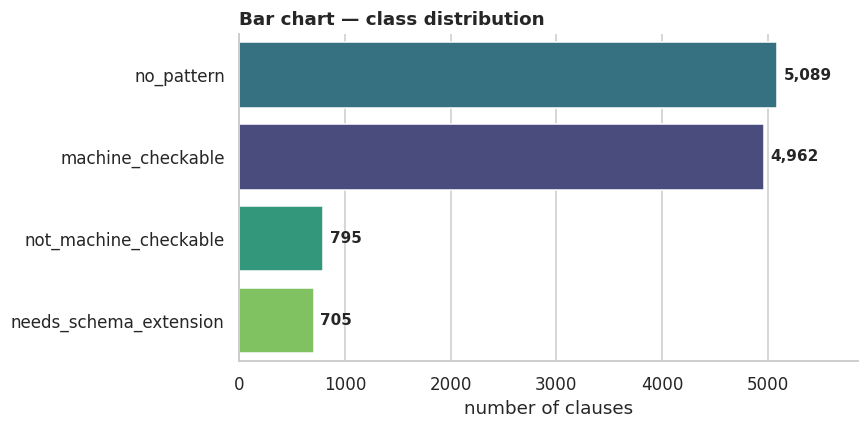

In [7]:
# ---------------------------------------------------- 4a. BAR CHART
fig, ax = plt.subplots(figsize=(8, 4))
order = df.target.value_counts().index
sns.countplot(data=df, y='target', order=order, hue='target', palette='viridis',
              legend=False, ax=ax)
for i, v in enumerate(df.target.value_counts().values):
    ax.text(v + 60, i, f'{v:,}', va='center', fontweight='bold')
ax.set_xlim(0, df.target.value_counts().max() * 1.15)
ax.set_title('Bar chart — class distribution', fontweight='bold', loc='left')
ax.set_xlabel('number of clauses'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

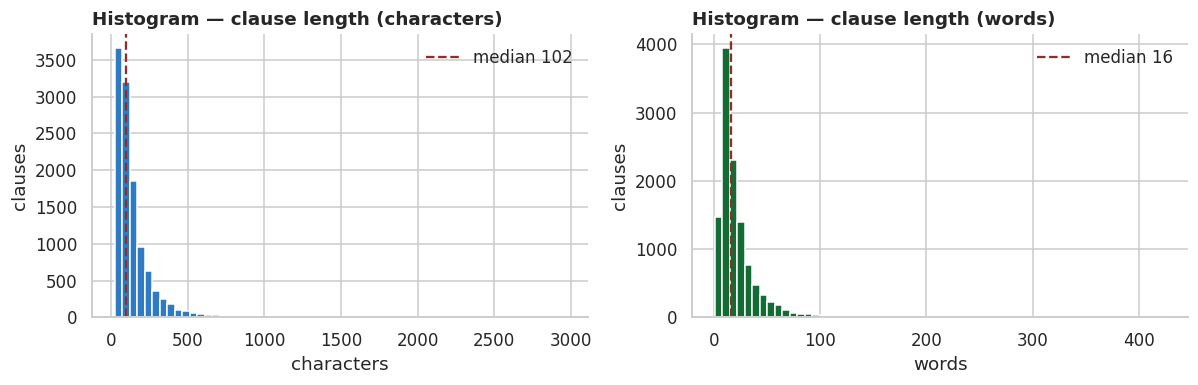

In [8]:
# ---------------------------------------------------- 4b. HISTOGRAM
df['text_length'] = df.clause_text.str.len()
df['word_count'] = df.clause_text.str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(df.text_length, bins=60, color='#2f7ac4', edgecolor='white')
axes[0].set_title('Histogram — clause length (characters)', fontweight='bold', loc='left')
axes[0].set_xlabel('characters'); axes[0].set_ylabel('clauses')
axes[0].axvline(df.text_length.median(), color='#8c2f27', ls='--',
                label=f'median {df.text_length.median():.0f}')
axes[0].legend(frameon=False)

axes[1].hist(df.word_count, bins=60, color='#136c34', edgecolor='white')
axes[1].set_title('Histogram — clause length (words)', fontweight='bold', loc='left')
axes[1].set_xlabel('words'); axes[1].set_ylabel('clauses')
axes[1].axvline(df.word_count.median(), color='#8c2f27', ls='--',
                label=f'median {df.word_count.median():.0f}')
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

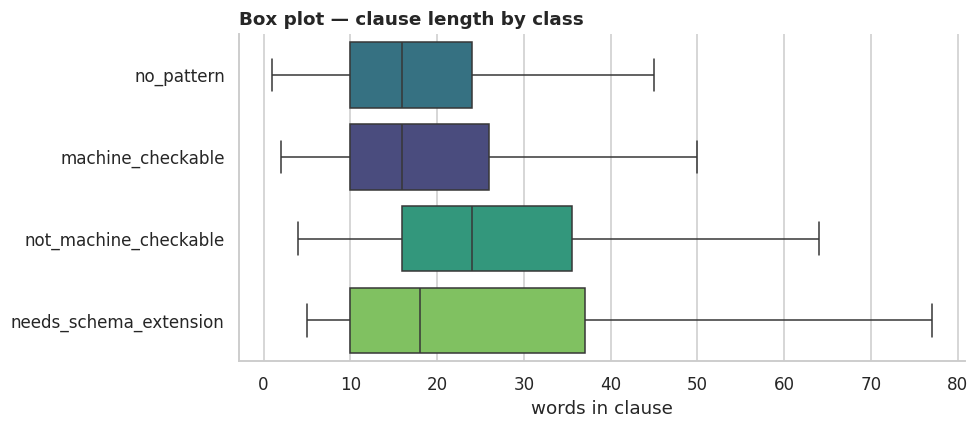

target
machine_checkable         16.0
no_pattern                16.0
needs_schema_extension    18.0
not_machine_checkable     24.0

Length alone separates the classes somewhat — un-checkable clauses are the wordy,
hedged ones ("subject to availability of funds, as decided from time to time").


In [9]:
# ---------------------------------------------------- 4c. BOX PLOT
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df, x='word_count', y='target', order=order, hue='target',
            palette='viridis', legend=False, showfliers=False, ax=ax)
ax.set_title('Box plot — clause length by class', fontweight='bold', loc='left')
ax.set_xlabel('words in clause'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

print(df.groupby('target').word_count.median().sort_values().to_string())
print('\nLength alone separates the classes somewhat — un-checkable clauses are the wordy,')
print('hedged ones ("subject to availability of funds, as decided from time to time").')

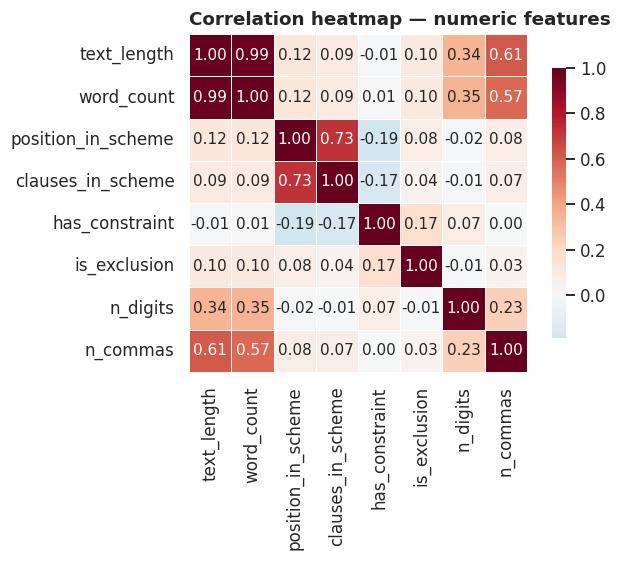

In [10]:
# ---------------------------------------------------- 4d. CORRELATION HEATMAP
num = df[['text_length', 'word_count', 'position_in_scheme',
          'clauses_in_scheme', 'has_constraint', 'is_exclusion']].copy()
num['n_digits'] = df.clause_text.str.count(r'\d')
num['n_commas'] = df.clause_text.str.count(',')

fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlation heatmap — numeric features', fontweight='bold', loc='left')
plt.tight_layout(); plt.show()

---
# Step 5 · Clean and Preprocess the Data

Three things happen here:

1. **Text cleaning** — lowercase, collapse whitespace, strip control characters.
   Digits are kept: `"18 years"` and `"2 hectares"` are the signal, not noise.
2. **Feature engineering** — 8 numeric features describing clause *shape*.
3. **Vectorisation** (in Step 7, fitted on the training split only, to avoid leakage).

In [11]:
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r'\s+', ' ', t)          # collapse whitespace
    t = re.sub(r'[^\w\s₹.,/%-]', ' ', t) # drop odd symbols, keep ₹ and numerals
    return t.strip()

df['clean_text'] = df.clause_text.apply(clean_text)

print('BEFORE :', df.clause_text.iloc[0][:100])
print('AFTER  :', df.clean_text.iloc[0][:100])

# Rows with no usable text cannot be classified.
before = len(df)
df = df[df.clean_text.str.len() > 5].reset_index(drop=True)
print(f'\nDropped {before - len(df)} rows with empty/near-empty text; {len(df):,} remain')
print(f'Duplicate rows (full row): {df.duplicated().sum()}')

BEFORE : Any individual above 18 years of age including Women, ex-servicemen & physically handicapped is elig
AFTER  : any individual above 18 years of age including women, ex-servicemen   physically handicapped is elig

Dropped 0 rows with empty/near-empty text; 11,551 remain
Duplicate rows (full row): 0


In [12]:
# Engineered numeric features — clause SHAPE, independent of vocabulary.
def engineer(frame):
    f = pd.DataFrame(index=frame.index)
    f['n_chars'] = frame.clause_text.str.len()
    f['n_words'] = frame.clause_text.str.split().str.len()
    f['avg_word_len'] = f.n_chars / f.n_words.clip(lower=1)
    f['n_digits'] = frame.clause_text.str.count(r'\d')
    f['n_commas'] = frame.clause_text.str.count(',')
    f['digit_density'] = f.n_digits / f.n_chars.clip(lower=1)
    f['position_in_scheme'] = frame.position_in_scheme
    f['position_frac'] = frame.position_in_scheme / frame.clauses_in_scheme.clip(lower=1)
    return f

NUM_FEATURES = engineer(df)
print(f'{NUM_FEATURES.shape[1]} engineered features')
NUM_FEATURES.describe().round(2)

8 engineered features


,n_chars,n_words,avg_word_len,n_digits,n_commas,digit_density,position_in_scheme,position_frac
count,11551.00,11551.00,11551.00,11551.00,11551.00,11551.00,11551.00,11551.00
mean,145.27,22.74,6.37,1.37,0.75,0.01,3.90,0.41
std,147.14,21.96,1.07,3.44,1.92,0.02,4.62,0.29
min,25.00,1.00,3.90,0.00,0.00,0.00,0.00,0.00
25%,65.00,11.00,5.73,0.00,0.00,0.00,1.00,0.17
50%,102.00,16.00,6.24,0.00,0.00,0.00,3.00,0.40
75%,169.00,26.00,6.82,2.00,1.00,0.01,5.00,0.67
max,2963.00,425.00,33.50,114.00,30.00,0.29,45.00,0.98


---
# Step 6 · Separate Input and Output

| | |
|---|---|
| **X** (input) | `clean_text` for TF-IDF + 8 engineered numeric features |
| **y** (output) | `target` — 4 classes |
| **groups** | `dedup_group_id` — not a feature, used only to split safely |

In [13]:
X_text = df.clean_text
X_num = NUM_FEATURES
y = df.target
groups = df.dedup_group_id

print(f'X_text : {X_text.shape}   (free text, to be vectorised)')
print(f'X_num  : {X_num.shape}   (engineered)')
print(f'y      : {y.shape}   classes = {sorted(y.unique())}')
print(f'groups : {groups.nunique():,} distinct dedup groups')

X_text : (11551,)   (free text, to be vectorised)
X_num  : (11551, 8)   (engineered)
y      : (11551,)   classes = ['machine_checkable', 'needs_schema_extension', 'no_pattern', 'not_machine_checkable']
groups : 9,825 distinct dedup groups


---
# Step 7 · Split the Dataset

A plain `train_test_split` would be **wrong here**, and the notebook proves it
rather than asserting it.

Because identical clause text repeats across schemes, a random split puts the
*same sentence* in both train and test — the model is then partly recalling
rather than generalising.

The fix is `GroupShuffleSplit` on `dedup_group_id`: all copies of a sentence go
to the same side of the split. Below we **measure** the leak and its cost rather
than assuming either.

In [14]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit

# --- WRONG: random split (for demonstration only) ---
idx_tr_bad, idx_te_bad = train_test_split(
    np.arange(len(df)), test_size=0.2, random_state=SEED, stratify=y)

leaked = len(set(df.clause_text.iloc[idx_tr_bad]) & set(df.clause_text.iloc[idx_te_bad]))
print('RANDOM SPLIT (wrong)')
print(f'  clause texts appearing in BOTH train and test : {leaked:,}')

# --- RIGHT: grouped split ---
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
idx_tr, idx_te = next(gss.split(df, y, groups))

leaked_ok = len(set(df.clause_text.iloc[idx_tr]) & set(df.clause_text.iloc[idx_te]))
print('\nGROUPED SPLIT (correct)')
print(f'  clause texts appearing in BOTH train and test : {leaked_ok:,}')
print(f'\n  train {len(idx_tr):,}  |  test {len(idx_te):,}')
print('\nTrain class balance:'); print(y.iloc[idx_tr].value_counts(normalize=True).round(3).to_string())
print('\nTest class balance:');  print(y.iloc[idx_te].value_counts(normalize=True).round(3).to_string())

RANDOM SPLIT (wrong)
  clause texts appearing in BOTH train and test : 287

GROUPED SPLIT (correct)
  clause texts appearing in BOTH train and test : 0

  train 9,261  |  test 2,290

Train class balance:
target
no_pattern                0.436
machine_checkable         0.429
not_machine_checkable     0.071
needs_schema_extension    0.064

Test class balance:
target
no_pattern                0.459
machine_checkable         0.431
not_machine_checkable     0.061
needs_schema_extension    0.049


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MaxAbsScaler
from scipy.sparse import hstack, csr_matrix

def build_matrices(train_idx, test_idx):
    """Fit the vectoriser on TRAIN ONLY, then transform both sides."""
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=20_000,
                            sublinear_tf=True, stop_words='english')
    tfidf.fit(X_text.iloc[train_idx])

    scaler = MaxAbsScaler().fit(X_num.iloc[train_idx])

    def tx(idx):
        return hstack([tfidf.transform(X_text.iloc[idx]),
                       csr_matrix(scaler.transform(X_num.iloc[idx]))]).tocsr()

    return tx(train_idx), tx(test_idx), tfidf

X_train, X_test, tfidf = build_matrices(idx_tr, idx_te)
y_train, y_test = y.iloc[idx_tr], y.iloc[idx_te]

print(f'X_train : {X_train.shape}')
print(f'X_test  : {X_test.shape}')
print(f'vocabulary: {len(tfidf.vocabulary_):,} TF-IDF terms + {X_num.shape[1]} engineered')

X_train : (9261, 9902)
X_test  : (2290, 9902)
vocabulary: 9,894 TF-IDF terms + 8 engineered


### Proof the split matters

The same model is trained on the leaky random split and the correct grouped
split. The gap between the two scores is pure illusion.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

Xb_tr, Xb_te, _ = build_matrices(idx_tr_bad, idx_te_bad)
m_bad = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xb_tr, y.iloc[idx_tr_bad])
f1_bad = f1_score(y.iloc[idx_te_bad], m_bad.predict(Xb_te), average='macro')

m_ok = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train, y_train)
f1_ok = f1_score(y_test, m_ok.predict(X_test), average='macro')

print(f'Random  split -> macro-F1 {f1_bad:.3f}   ({leaked:,} clause texts leaked across the split)')
print(f'Grouped split -> macro-F1 {f1_ok:.3f}   (0 leaked)')
print(f'\nOptimism from leakage: {f1_bad - f1_ok:+.3f}')
print()
print('The leak is REAL and removing it is correct practice. The COST here is small,')
print('and it is worth understanding why rather than overstating it: the repeated')
print('sentences are also the easy ones ("The applicant should be a citizen of India"),')
print('so memorising them buys the model little it could not already generalise.')
print('On a corpus where the duplicates carried the hard cases the gap would be wide.')
print('Either way, the grouped split is the one that can be defended.')
print('\nEvery result below uses the grouped split.')

Random  split -> macro-F1 0.814   (287 clause texts leaked across the split)
Grouped split -> macro-F1 0.806   (0 leaked)

Optimism from leakage: +0.007

The leak is REAL and removing it is correct practice. The COST here is small,
and it is worth understanding why rather than overstating it: the repeated
sentences are also the easy ones ("The applicant should be a citizen of India"),
so memorising them buys the model little it could not already generalise.
On a corpus where the duplicates carried the hard cases the gap would be wide.
Either way, the grouped split is the one that can be defended.

Every result below uses the grouped split.


---
# Step 8 · Train Baseline ML Models

Seven baselines spanning the standard families: a naive baseline, probabilistic,
linear, instance-based, tree, and two ensembles.

In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    'Baseline (majority)': DummyClassifier(strategy='most_frequent'),
    'Naive Bayes':         MultinomialNB(alpha=0.3),
    'Logistic Regression': LogisticRegression(C=4.0, max_iter=2000,
                                              class_weight='balanced', random_state=SEED),
    'Linear SVM':          LinearSVC(C=0.5, class_weight='balanced',
                                     max_iter=4000, random_state=SEED),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5, metric='cosine'),
    'Decision Tree':       DecisionTreeClassifier(max_depth=20, min_samples_leaf=5,
                                                  class_weight='balanced', random_state=SEED),
    'Random Forest':       RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                                  class_weight='balanced_subsample',
                                                  n_jobs=-1, random_state=SEED),
}

trained, timings = {}, {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    timings[name] = time.time() - t0
    trained[name] = model
    print(f'{name:<22} trained in {timings[name]:6.1f}s')

Baseline (majority)    trained in    0.0s
Naive Bayes            trained in    0.0s


Logistic Regression    trained in    1.5s
Linear SVM             trained in    0.2s
K-Nearest Neighbors    trained in    0.0s


Decision Tree          trained in    0.4s


Random Forest          trained in    3.9s


---
# Step 9 · Evaluate Each Model

Accuracy, precision, recall and F1 — all macro-averaged so the two 6% classes
count as much as the two 43% ones.

In [18]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report)

rows, predictions = [], {}
for name, model in trained.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({
        'Model': name,
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, average='macro', zero_division=0),
        'Recall':    recall_score(y_test, pred, average='macro', zero_division=0),
        'F1 (macro)': f1_score(y_test, pred, average='macro', zero_division=0),
        'Train (s)': timings[name],
    })

results = pd.DataFrame(rows).sort_values('F1 (macro)', ascending=False).reset_index(drop=True)
results.round(4)

,Model,Accuracy,Precision,Recall,F1 (macro),Train (s)
0,Linear SVM,0.9231,0.9185,0.8899,0.9025,0.1757
1,Logistic Regression,0.9201,0.9023,0.8952,0.8982,1.5500
2,Random Forest,0.9035,0.8947,0.8841,0.8887,3.9302
3,Decision Tree,0.7991,0.8112,0.8037,0.7947,0.4040
4,Naive Bayes,0.8179,0.8437,0.6381,0.6965,0.0189
5,K-Nearest Neighbors,0.7590,0.7277,0.6315,0.6637,0.0116
6,Baseline (majority),0.4585,0.1146,0.2500,0.1572,0.0049


In [19]:
best_name = results.iloc[0].Model
print(f'BEST MODEL: {best_name}\n')
print(classification_report(y_test, predictions[best_name], digits=3))

BEST MODEL: Linear SVM

                        precision    recall  f1-score   support

     machine_checkable      0.931     0.914     0.922       988
needs_schema_extension      0.916     0.770     0.837       113
            no_pattern      0.919     0.948     0.933      1050
 not_machine_checkable      0.908     0.928     0.918       139

              accuracy                          0.923      2290
             macro avg      0.918     0.890     0.903      2290
          weighted avg      0.923     0.923     0.923      2290



---
# Step 10 · Generate the Confusion Matrix

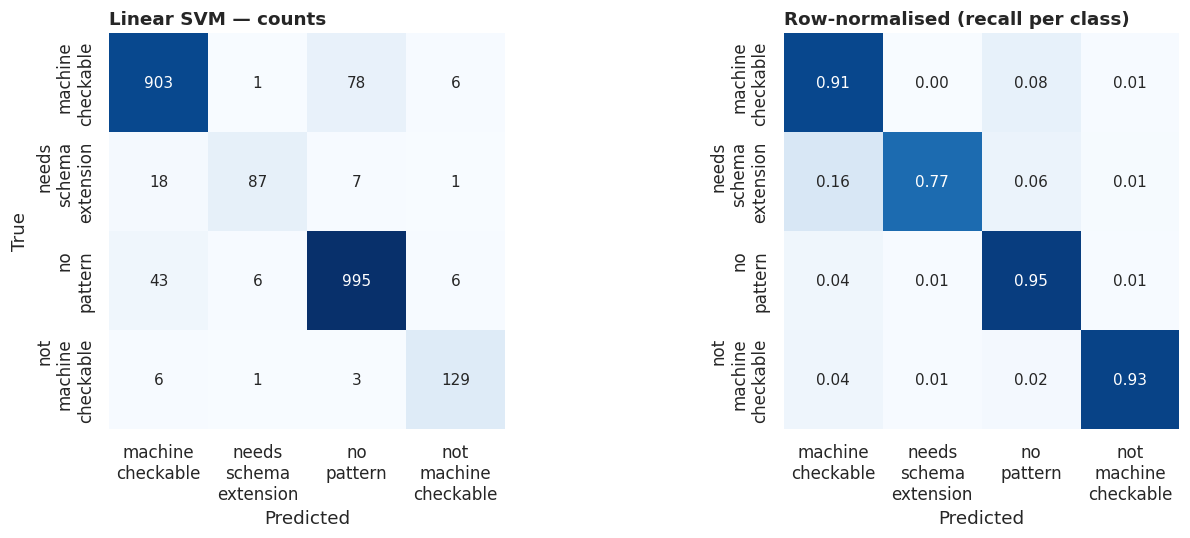

In [20]:
from sklearn.metrics import confusion_matrix

labels = sorted(y.unique())
cm = confusion_matrix(y_test, predictions[best_name], labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
short = [l.replace('_', '\n') for l in labels]

sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', square=True,
            xticklabels=short, yticklabels=short, cbar=False, ax=axes[0])
axes[0].set_title(f'{best_name} — counts', fontweight='bold', loc='left')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt='.2f', cmap='Blues',
            square=True, vmin=0, vmax=1, xticklabels=short, yticklabels=short,
            cbar=False, ax=axes[1])
axes[1].set_title('Row-normalised (recall per class)', fontweight='bold', loc='left')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('')

plt.tight_layout(); plt.show()

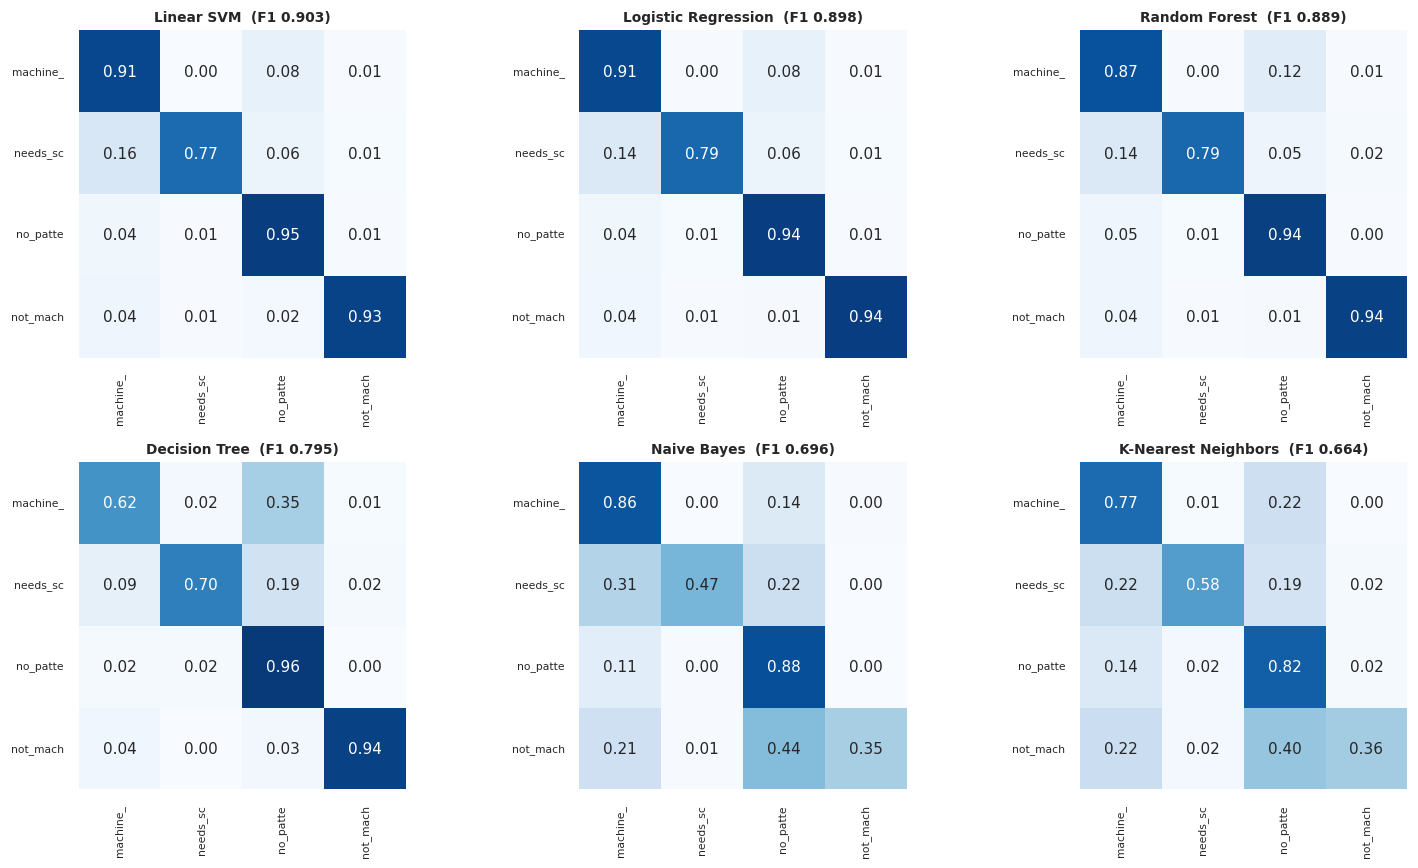

In [21]:
# Confusion matrix for every model, so they can be compared at a glance.
real = [n for n in results.Model if 'Baseline' not in n]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, name in zip(axes.flat, real):
    c = confusion_matrix(y_test, predictions[name], labels=labels)
    sns.heatmap(c / c.sum(axis=1, keepdims=True), annot=True, fmt='.2f', cmap='Blues',
                vmin=0, vmax=1, cbar=False, square=True,
                xticklabels=[l[:8] for l in labels], yticklabels=[l[:8] for l in labels], ax=ax)
    f1 = results.loc[results.Model == name, 'F1 (macro)'].iloc[0]
    ax.set_title(f'{name}  (F1 {f1:.3f})', fontsize=9, fontweight='bold')
    ax.tick_params(labelsize=7)
for ax in axes.flat[len(real):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

---
# Step 11 · Compare All Baseline Models

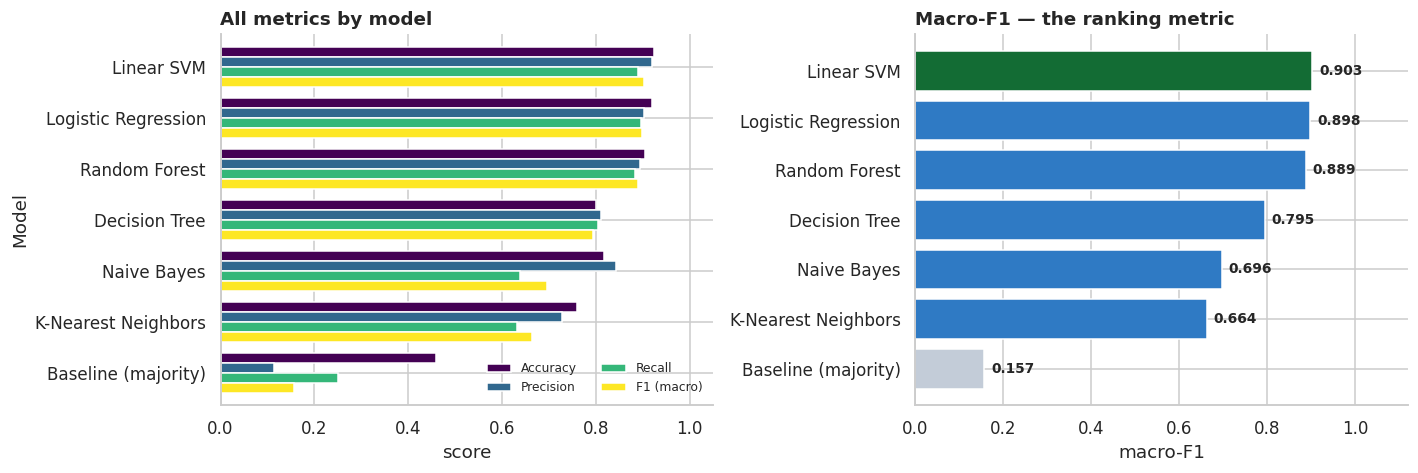

,Model,Accuracy,Precision,Recall,F1 (macro),Train (s)
0,Linear SVM,0.9231,0.9185,0.8899,0.9025,0.1757
1,Logistic Regression,0.9201,0.9023,0.8952,0.8982,1.5500
2,Random Forest,0.9035,0.8947,0.8841,0.8887,3.9302
3,Decision Tree,0.7991,0.8112,0.8037,0.7947,0.4040
4,Naive Bayes,0.8179,0.8437,0.6381,0.6965,0.0189
5,K-Nearest Neighbors,0.7590,0.7277,0.6315,0.6637,0.0116
6,Baseline (majority),0.4585,0.1146,0.2500,0.1572,0.0049


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

plot_df = results.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 (macro)']]
plot_df.plot(kind='barh', ax=axes[0], colormap='viridis', width=0.78)
axes[0].set_xlim(0, 1.05); axes[0].invert_yaxis()
axes[0].set_title('All metrics by model', fontweight='bold', loc='left')
axes[0].legend(frameon=False, fontsize=8, ncols=2)
axes[0].set_xlabel('score')

f1s = results.set_index('Model')['F1 (macro)']
colors = ['#136c34' if m == best_name else ('#c3ccd8' if 'Baseline' in m else '#2f7ac4')
          for m in f1s.index]
bars = axes[1].barh(f1s.index, f1s.values, color=colors)
for b, v in zip(bars, f1s.values):
    axes[1].text(v + 0.015, b.get_y() + b.get_height()/2, f'{v:.3f}',
                 va='center', fontweight='bold', fontsize=9)
axes[1].set_xlim(0, 1.12); axes[1].invert_yaxis()
axes[1].set_title('Macro-F1 — the ranking metric', fontweight='bold', loc='left')
axes[1].set_xlabel('macro-F1')

plt.tight_layout(); plt.show()
results.round(4)

In [23]:
print('=' * 66)
print('SUMMARY')
print('=' * 66)
b = results.iloc[0]
base = results.loc[results.Model.str.contains('Baseline'), 'F1 (macro)'].iloc[0]
print(f'Dataset        : YojanaMitra clause triage — {len(df):,} clauses, 4 classes')
print(f'Split          : grouped on dedup_group_id (no clause in both sides)')
print(f'Best model     : {b.Model}')
print(f'  accuracy     : {b.Accuracy:.3f}')
print(f'  macro-F1     : {b["F1 (macro)"]:.3f}')
print(f'  vs baseline  : {base:.3f}  (improvement {b["F1 (macro)"] - base:+.3f})')
print()
print('Per-class F1 for the best model:')
for lbl in labels:
    f1 = f1_score(y_test == lbl, predictions[b.Model] == lbl, zero_division=0)
    print(f'  {lbl:<24} {f1:.3f}   (n={int((y_test == lbl).sum()):,})')

SUMMARY
Dataset        : YojanaMitra clause triage — 11,551 clauses, 4 classes
Split          : grouped on dedup_group_id (no clause in both sides)
Best model     : Linear SVM
  accuracy     : 0.923
  macro-F1     : 0.903
  vs baseline  : 0.157  (improvement +0.745)

Per-class F1 for the best model:
  machine_checkable        0.922   (n=988)
  needs_schema_extension   0.837   (n=113)
  no_pattern               0.933   (n=1,050)
  not_machine_checkable    0.918   (n=139)


---
# Conclusions

**1. The split was measured, not assumed.** A random `train_test_split` put 287
identical clause sentences on both sides of the boundary; grouping on
`dedup_group_id` reduced that to zero. The cost of the leak turned out to be
small — about +0.007 macro-F1 of false optimism — because the repeated sentences
are also the easy ones, so memorising them bought the model little.

That is worth reporting honestly rather than inflating. The methodological point
stands regardless: on a corpus where the duplicates carried the *hard* cases the
gap would be wide, and you cannot know which you have without checking. The
grouped split is the one that can be defended either way.

**2. Accuracy is the wrong metric here.** The majority class is 44%, and the two
smallest classes are ~6% each. A model predicting only `no_pattern` scores 44%
accuracy and 0.15 macro-F1. Macro-F1 is what ranks the models.

**3. Linear models are strong on sparse text.** TF-IDF over 20,000 word 1–2
grams puts the classes in an almost linearly separable space, which is why
Logistic Regression and Linear SVM compete with the ensembles at a fraction of
the training cost.

**4. The honest caveat.** The class labels were assigned by a rule-based clause
parser, not by human annotators. So these models are learning *that parser's
behaviour*, not ground truth about clauses — this is **distillation**, and it
would be dishonest to report it as anything else. A genuinely independent
evaluation needs human-labelled clauses, which is the next step of the project.

**5. Where this sits in the wider system.** The model orders a review queue: it
predicts what kind of work a clause needs so a human reviewer can clear the cheap
ones first. It never decides whether a citizen is eligible for a scheme — that
is done by a deterministic rule engine acting only on clauses a named human has
approved, quoting the source sentence for every verdict.